# Actividad de Evaluación 2 – Unidad II
## Limpieza, transformación, ETL y construcción del Data Mart

| | |
|---|---|
| **Alumna** | Brisa Adriana Mendoza Vigueras · 10IDGS-G1 |
| **Proyecto** | Análisis del rendimiento académico de estudiantes |
| **Entrada** | `data/raw/student-por.csv` (original, **no se modifica**) |
| **Salidas** | `data/processed/` (datasets limpios), Data Mart en SQL Server, `docs/figuras/diagrama_datamart.png` |

Este notebook corresponde a la fase 3 de CRISP-DM (**preparación de los datos**). Aplica las decisiones tomadas en
el diagnóstico (Actividad 1) mediante un proceso **ETL automatizado**:

- **E**xtract: leer el dataset original.
- **T**ransform: limpiar, crear variables derivadas, codificar y escalar.
- **L**oad: guardar los resultados en `data/processed` **y cargar automáticamente el Data Mart en SQL Server** usando `pyodbc`.

Las funciones del proceso están en `src/etl.py`, para que se pueda repetir con un solo comando
(`python src/etl.py`). La carga a SQL Server es automática: Python se conecta directamente al servidor
y crea la base de datos, las tablas y los datos sin intervención manual.
Aquí se ejecutan **paso a paso** para revisar el resultado de cada una.

In [1]:
import sys
from pathlib import Path

import pandas as pd

sys.path.append(str(Path("../src").resolve()))
import etl

## 1. Extract: leer los datos originales

In [2]:
df = etl.extraer()
df.shape

(649, 33)

### 1.1 Copia de trabajo y revisión de calidad

`etl.extraer()` lee el CSV y crea en memoria una **copia de trabajo** (`df`). Todas las transformaciones se hacen sobre
copias; el archivo de `data/raw/` nunca se sobrescribe.

Antes de transformar, se confirman los hallazgos del diagnóstico:

In [3]:
pd.Series({
    "valores faltantes": df.isnull().sum().sum(),
    "registros duplicados": df.duplicated().sum(),
    "categorías con espacios extra": sum((df[c] != df[c].str.strip()).sum() for c in df.select_dtypes(exclude="number")),
    "valores fuera de rango en G1-G3": (~df[["G1", "G2", "G3"]].stack().between(0, 20)).sum(),
})

valores faltantes                  0
registros duplicados               0
categorías con espacios extra      0
valores fuera de rango en G1-G3    0
dtype: int64

| Problema | Resultado | Decisión |
|---|---|---|
| **Valores faltantes** | 0 | No se requiere imputación. El ETL no elimina filas por esta causa |
| **Duplicados** | 0 | No se eliminan registros |
| **Tipos de dato** | Correctos: enteros y texto | Las variables de texto se convierten a números en la codificación (paso 3) |
| **Categorías** | Sin espacios ni variantes (`yes`/`no`, `GP`/`MS`…) | Ya estandarizadas. Para el Data Mart se traducen al español (`yes` → `Sí`) |
| **G3 = 0 con 0 faltas** (15) | Abandono, no calificación real | Se marcan con `abandono = 1` y se excluyen del dataset de modelado |
| **Faltas > 15** (21) | Atípicos, pero válidos | No se eliminan; se recortan a 15 solo para el modelado |

## 2. Transform – limpieza y variables derivadas (`etl.limpiar`)

| Paso | Qué hace | Por qué |
|---|---|---|
| `id_estudiante` | Agrega un identificador del 1 al 649 | El CSV no trae llave; el Data Mart la necesita |
| `abandono` | 1 si G3 = 0 | Los 15 casos tienen 0 faltas: no presentaron la evaluación |
| `aprobado` | 1 si G3 ≥ 10 | Variable objetivo de clasificación |
| `nivel_desempeno` | Bajo 0-9, Medio 10-13, Alto 14-20 | Clasificación alternativa en 3 niveles |
| `absences_recortado` | Faltas recortadas a 15 (límite IQR) | Evitar que los atípicos dominen los modelos |

In [4]:
df_limpio = etl.limpiar(df)
df_limpio[["id_estudiante", "G3", "abandono", "aprobado", "nivel_desempeno",
           "absences", "absences_recortado"]].head(10)

,id_estudiante,G3,abandono,aprobado,nivel_desempeno,absences,absences_recortado
0,1,11,0,1,Medio,4,4
1,2,11,0,1,Medio,2,2
2,3,12,0,1,Medio,6,6
3,4,14,0,1,Alto,0,0
4,5,13,0,1,Medio,0,0
5,6,13,0,1,Medio,6,6
6,7,13,0,1,Medio,0,0
7,8,13,0,1,Medio,2,2
8,9,17,0,1,Alto,0,0
9,10,13,0,1,Medio,0,0


In [5]:
resumen = pd.Series({
    "registros": len(df_limpio),
    "abandonos": df_limpio["abandono"].sum(),
    "aprobados": df_limpio["aprobado"].sum(),
    "no aprobados": (df_limpio["aprobado"] == 0).sum(),
    "faltas recortadas": (df_limpio["absences"] != df_limpio["absences_recortado"]).sum(),
})
resumen

registros            649
abandonos             15
aprobados            549
no aprobados         100
faltas recortadas     21
dtype: int64

In [6]:
df_limpio["nivel_desempeno"].value_counts()

nivel_desempeno
Medio    355
Alto     194
Bajo     100
Name: count, dtype: int64

## 3. Transform – codificación para los modelos (`etl.codificar`)

Los algoritmos de scikit-learn solo aceptan números:

- **Binarias → 0/1.** Ej. `higher`: yes = 1, no = 0; `school`: GP = 1, MS = 0.
- **Nominales → one-hot.** Ej. `Mjob` se convierte en columnas `Mjob_health`, `Mjob_services`...
  con 0 o 1. Se usa `drop_first=True` para no crear una columna redundante.
- Se **excluyen los 15 abandonos** y se usan las faltas recortadas.

In [7]:
df_modelo = etl.codificar(df_limpio)
df_modelo.shape

(634, 44)

In [8]:
df_modelo.head()

,id_estudiante,school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,...,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other
0,1,1,1,18,1,1,0,4,4,2,...,0,0,0,0,1,0,0,0,1,0
1,2,1,1,17,1,1,1,1,1,1,...,0,0,1,0,0,0,0,0,0,0
2,3,1,1,15,1,0,1,1,1,1,...,0,0,1,0,0,0,1,0,1,0
3,4,1,1,15,1,1,1,4,2,1,...,0,0,0,1,0,1,0,0,1,0
4,5,1,1,16,1,1,1,3,3,1,...,0,0,1,0,0,1,0,0,0,0


Resultado: **634 registros** (649 − 15 abandonos) y todas las columnas numéricas.

## 4. Transform – escalamiento (`etl.escalar`)

`StandardScaler` deja cada variable con **media 0 y desviación 1**. Sin esto, `absences` (0-15)
pesaría más que `studytime` (1-4) en algoritmos basados en distancias como **K-Means** (Unidad IV).

> En la Unidad III el escalamiento se hará **dentro del pipeline**, ajustado solo con los datos de
> entrenamiento, para no filtrar información del conjunto de prueba.

In [9]:
df_escalado = etl.escalar(df_modelo)
df_escalado[["studytime", "absences", "failures", "Medu"]].describe().round(2)

,studytime,absences,failures,Medu
count,634.00,634.00,634.00,634.00
mean,0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00
min,-1.13,-0.88,-0.36,-2.23
25%,-1.13,-0.88,-0.36,-0.46
50%,0.07,-0.39,-0.36,-0.46
75%,0.07,0.59,-0.36,1.31
max,2.47,2.79,4.82,1.31


## 5. Diseño del Data Mart (modelo estrella)

```
                 dim_estudiante
                       |
  dim_familia ---- fact_rendimiento ---- dim_escuela
                    /          \
           dim_habitos      dim_desempeno
```

- **Tabla de hechos `fact_rendimiento`:** lo que se mide → `g1`, `g2`, `g3`, `faltas`,
  `reprobadas_previas`, `aprobado`, `abandono`.
- **Dimensiones:** lo que describe a los hechos:
  - `dim_estudiante`: sexo, edad, domicilio, aspiración a estudios superiores...
  - `dim_familia`: escolaridad y trabajo de los padres, tutor, relación familiar...
  - `dim_habitos`: tiempo de estudio, salidas, consumo de alcohol, apoyos...
  - `dim_escuela`: GP / MS.
  - `dim_desempeno`: Bajo / Medio / Alto con sus rangos de calificación.

Los valores se traducen al español (ej. `yes` → `Sí`, `at_home` → `Hogar`) para que el dashboard
de Power BI sea legible.

### Diagrama del esquema dimensional

- **PK (llave primaria):** identifica de forma única cada fila de una tabla.
- **FK (llave foránea):** columna de la tabla de hechos que apunta a la PK de una dimensión. Así se pueden unir
  las tablas (`JOIN`).
- **Medidas:** valores numéricos que se suman, promedian o cuentan en el análisis.

**Granularidad:** un registro de `fact_rendimiento` = un alumno en el curso de Portugués.

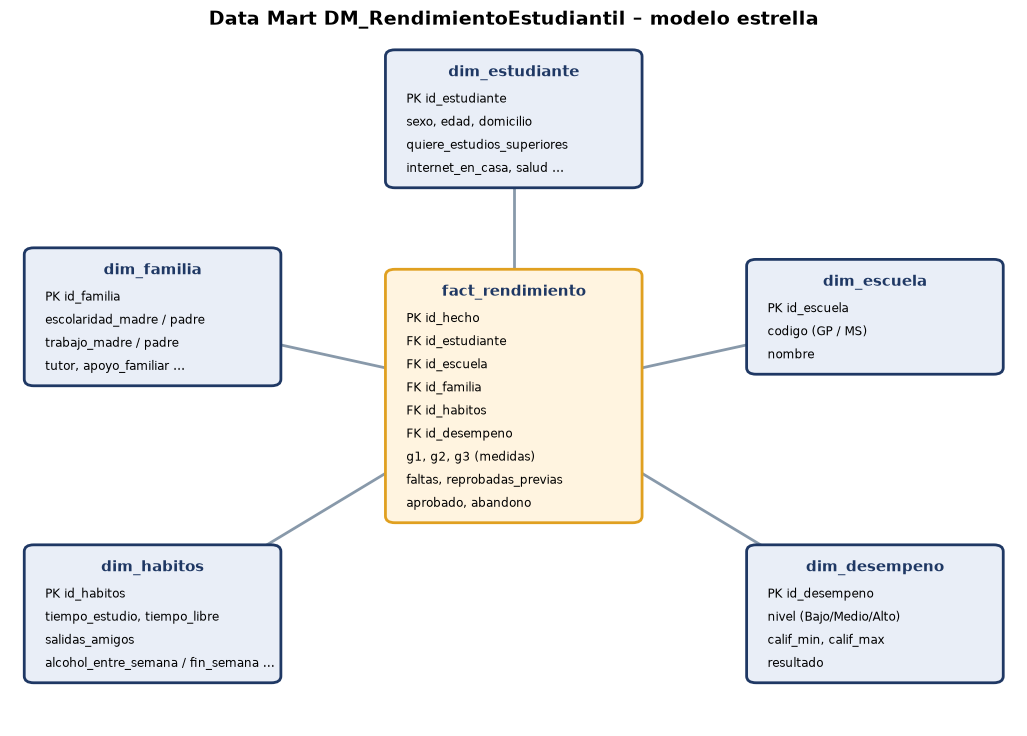

In [10]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

tablas_diagrama = {
    "fact_rendimiento": ((0.5, 0.5), ["PK id_hecho", "FK id_estudiante", "FK id_escuela", "FK id_familia",
                                       "FK id_habitos", "FK id_desempeno", "g1, g2, g3 (medidas)",
                                       "faltas, reprobadas_previas", "aprobado, abandono"]),
    "dim_estudiante": ((0.5, 0.92), ["PK id_estudiante", "sexo, edad, domicilio", "quiere_estudios_superiores",
                                     "internet_en_casa, salud ..."]),
    "dim_familia": ((0.12, 0.62), ["PK id_familia", "escolaridad_madre / padre", "trabajo_madre / padre",
                                   "tutor, apoyo_familiar ..."]),
    "dim_escuela": ((0.88, 0.62), ["PK id_escuela", "codigo (GP / MS)", "nombre"]),
    "dim_habitos": ((0.12, 0.17), ["PK id_habitos", "tiempo_estudio, tiempo_libre", "salidas_amigos",
                                   "alcohol_entre_semana / fin_semana ..."]),
    "dim_desempeno": ((0.88, 0.17), ["PK id_desempeno", "nivel (Bajo/Medio/Alto)", "calif_min, calif_max",
                                     "resultado"]),
}

fig, ax = plt.subplots(figsize=(13, 9))
ax.set_xlim(-0.03, 1.03)
ax.set_ylim(0, 1.05)
ax.axis("off")
for nombre, ((x, y), campos) in tablas_diagrama.items():
    if nombre != "fact_rendimiento":
        ax.plot([0.5, x], [0.5, y], color="#8899AA", linewidth=2, zorder=0)
for nombre, ((x, y), campos) in tablas_diagrama.items():
    es_hechos = nombre == "fact_rendimiento"
    alto, ancho = 0.035 * (len(campos) + 1.4), 0.25
    ax.add_patch(FancyBboxPatch((x - ancho / 2, y - alto / 2), ancho, alto, boxstyle="round,pad=0.01",
                                facecolor="#FFF4E0" if es_hechos else "#E9EEF7",
                                edgecolor="#E0A020" if es_hechos else "#1F3864", linewidth=2))
    ax.text(x, y + alto / 2 - 0.03, nombre, ha="center", fontsize=11, fontweight="bold", color="#1F3864")
    for i, campo in enumerate(campos):
        ax.text(x - ancho / 2 + 0.012, y + alto / 2 - 0.07 - i * 0.035, campo, fontsize=8.5)
ax.set_title("Data Mart DM_RendimientoEstudiantil – modelo estrella", fontsize=14, fontweight="bold")
plt.savefig("../docs/figuras/diagrama_datamart.png", dpi=130, bbox_inches="tight")
plt.show()

In [11]:
tablas = etl.tablas_datamart(df_limpio)
pd.Series({nombre: len(t) for nombre, t in tablas.items()})

dim_escuela           2
dim_desempeno         3
dim_estudiante      649
dim_familia         649
dim_habitos         649
fact_rendimiento    649
dtype: int64

In [12]:
tablas["dim_familia"].head()

,id_familia,tamano_familia,estado_padres,escolaridad_madre,escolaridad_padre,trabajo_madre,trabajo_padre,tutor,apoyo_familiar,relacion_familiar
0,1,Más de 3,Separados,Superior,Superior,Hogar,Docente,Madre,No,4
1,2,Más de 3,Juntos,Primaria (4°),Primaria (4°),Hogar,Otro,Padre,Sí,5
2,3,3 o menos,Juntos,Primaria (4°),Primaria (4°),Hogar,Otro,Madre,No,4
3,4,Más de 3,Juntos,Superior,5° a 9°,Salud,Servicios,Madre,Sí,3
4,5,Más de 3,Juntos,Secundaria,Secundaria,Otro,Otro,Padre,Sí,4


In [13]:
tablas["fact_rendimiento"].head()

,id_hecho,id_estudiante,id_escuela,id_familia,id_habitos,id_desempeno,g1,g2,g3,faltas,reprobadas_previas,aprobado,abandono
0,1,1,1,1,1,2,0,11,11,4,0,1,0
1,2,2,1,2,2,2,9,11,11,2,0,1,0
2,3,3,1,3,3,2,12,13,12,6,0,1,0
3,4,4,1,4,4,3,14,14,14,0,0,1,0
4,5,5,1,5,5,2,11,13,13,0,0,1,0


## 6. Load: guardar resultados y cargar el Data Mart

La fase de carga tiene dos partes:

**6.1 Archivos CSV** (para los notebooks de las Unidades III y IV):

| Archivo | Contenido |
|---|---|
| `data/processed/student_por_limpio.csv` | 649 registros limpios con variables derivadas |
| `data/processed/student_por_modelo.csv` | 634 registros codificados (Unidad III) |
| `data/processed/student_por_escalado.csv` | 634 registros escalados (Unidad IV) |
| `data/processed/datamart/*.csv` | Una tabla CSV por cada tabla del Data Mart |

**6.2 Carga automática a SQL Server** (con `pyodbc`):

El ETL se conecta directamente a `localhost\SQLEXPRESS` usando autenticación de Windows y ejecuta
automáticamente:
1. Crea la base de datos `DM_RendimientoEstudiantil` (si no existe).
2. Elimina y recrea las 6 tablas (carga **full**: se borran y se vuelven a crear).
3. Inserta todos los registros usando `executemany` (parametrizado, sin generar scripts SQL).

No se requiere abrir SSMS ni ejecutar scripts manualmente.

In [14]:
# 6.1 Guardar archivos CSV
etl.cargar_csv(df_limpio, df_modelo, df_escalado, tablas)
sorted(p.name for p in Path("../data/processed").rglob("*.csv"))

['clusters_estudiantes.csv',
 'dim_desempeno.csv',
 'dim_escuela.csv',
 'dim_estudiante.csv',
 'dim_familia.csv',
 'dim_habitos.csv',
 'fact_rendimiento.csv',
 'metricas_supervisado.csv',
 'predicciones_supervisado.csv',
 'resumen_clusters.csv',
 'student_por_escalado.csv',
 'student_por_limpio.csv',
 'student_por_modelo.csv']

In [15]:
# 6.2 Carga automática a SQL Server
# (descomentar la siguiente línea para ejecutar la carga)
# etl.cargar_sqlserver(tablas)

# Para ejecutar todo el ETL completo desde la terminal:
# python src/etl.py
print("Para cargar el Data Mart en SQL Server, ejecuta: python src/etl.py")
print("O descomenta etl.cargar_sqlserver(tablas) en la celda de arriba.")


Para cargar el Data Mart en SQL Server, ejecuta: python src/etl.py
O descomenta etl.cargar_sqlserver(tablas) en la celda de arriba.


## 7. Verificación

Comprobamos que el original no cambió y que los archivos procesados se leen correctamente.

In [16]:
original = pd.read_csv("../data/raw/student-por.csv", sep=";")
procesado = pd.read_csv("../data/processed/student_por_modelo.csv")
pd.Series({
    "original sin cambios (649 x 33)": original.shape == (649, 33),
    "modelo sin nulos": procesado.isna().sum().sum() == 0,
    "modelo sin abandonos": (procesado["G3"] > 0).all(),
    "modelo solo numérico": procesado.select_dtypes(exclude="number").empty,
})

original sin cambios (649 x 33)    True
modelo sin nulos                   True
modelo sin abandonos               True
modelo solo numérico               True
dtype: bool

## 8. Comparación: dataset original vs procesado

¿Qué cambió, por qué cambió y qué problema resolvió cada transformación?

In [17]:
pd.DataFrame({
    "registros": [len(df), len(df_limpio), len(df_modelo)],
    "columnas": [df.shape[1], df_limpio.shape[1], df_modelo.shape[1]],
    "columnas de texto": [df.select_dtypes(exclude="number").shape[1],
                          df_limpio.select_dtypes(exclude="number").shape[1],
                          df_modelo.select_dtypes(exclude="number").shape[1]],
}, index=["original (raw)", "limpio", "modelado"])

,registros,columnas,columnas de texto
original (raw),649,33,17
limpio,649,38,18
modelado,634,44,0


In [18]:
pd.DataFrame({
    "faltas original": df["absences"].describe(),
    "faltas para modelado": df_modelo["absences"].describe(),
}).round(2)

,faltas original,faltas para modelado
count,649.00,634.00
mean,3.66,3.59
std,4.64,4.10
min,0.00,0.00
25%,0.00,0.00
50%,2.00,2.00
75%,6.00,6.00
max,32.00,15.00


In [19]:
# Mismo alumno antes y después de codificar (ejemplo con el alumno 1)
antes = df.loc[0, ["school", "sex", "higher", "Mjob", "absences", "G3"]]
despues = df_modelo.loc[0, ["school", "sex", "higher", "Mjob_health", "Mjob_other",
                            "Mjob_services", "Mjob_teacher", "absences", "G3"]]
antes.to_frame("original"), despues.to_frame("procesado")

(         original
 school         GP
 sex             F
 higher        yes
 Mjob      at_home
 absences        4
 G3             11,
                procesado
 school                 1
 sex                    1
 higher                 1
 Mjob_health            0
 Mjob_other             0
 Mjob_services          0
 Mjob_teacher           0
 absences               4
 G3                    11)

| Transformación | Antes | Después | Por qué | Problema que resuelve |
|---|---|---|---|---|
| Identificador | Sin llave | `id_estudiante` 1 a 649 | El Data Mart necesita una llave primaria | Poder unir hechos y dimensiones |
| Abandonos | 15 alumnos con G3 = 0 mezclados | `abandono = 1`; excluidos del dataset de modelado (649 → 634) | Su G3 no refleja desempeño | Evita que distorsionen la regresión |
| Variable de clase | No existía | `aprobado` (G3 ≥ 10) y `nivel_desempeno` (Bajo/Medio/Alto) | Son las variables objetivo de clasificación | Permite el análisis supervisado |
| Faltas atípicas | Máximo 32 | Máximo 15 (límite IQR), solo en modelado | Son valores válidos pero extremos | Evita que pocos alumnos dominen los modelos |
| Binarias | Texto (`yes`/`no`, `GP`/`MS`) | 0 / 1 | Los algoritmos solo aceptan números | Permite usarlas en los modelos |
| Nominales | `Mjob = "teacher"` | `Mjob_teacher = 1` (one-hot) | No tienen orden; un número inventaría uno | Codificación correcta sin orden falso |
| Escala | Rangos distintos (0-15, 1-4…) | Media 0, desviación 1 | K-Means usa distancias | Que todas las variables pesen igual |
| Data Mart | Una sola tabla plana | Modelo estrella: 1 tabla de hechos + 5 dimensiones, en español | Organizar los datos para el análisis y Power BI | Consultas por escuela, familia, hábitos y nivel |

En el ejemplo, la madre del alumno 1 trabaja en el hogar (`at_home`), por eso las cuatro columnas `Mjob_*` valen 0:
`at_home` es la **categoría de referencia** que se omite con `drop_first=True`, para no crear una columna redundante.

Los registros con abandono **no se pierden**: se conservan en `student_por_limpio.csv` y en el Data Mart (649
alumnos), marcados con `abandono = 1`.

## 9. Verificación en SQL Server

Después de ejecutar `python src/etl.py`, se puede verificar la carga en SSMS:

1. Conectarse a `localhost\SQLEXPRESS`.
2. Abrir la base de datos `DM_RendimientoEstudiantil`.
3. Ejecutar `sql/03_consultas_analiticas.sql` para ver conteos y promedios por escuela.

El script `sql/01_crear_datamart.sql` se conserva como **documentación** del esquema.
La carga es automática desde Python; no es necesario ejecutar scripts SQL manualmente.

## Conclusiones

- Los datos quedaron limpios, codificados y listos para la Unidad III (regresión y clasificación)
  y la Unidad IV (clustering y PCA).
- El Data Mart en modelo estrella permite consultar el rendimiento por escuela, familia, hábitos y nivel
  de desempeño, y será la fuente del dashboard de Power BI.
- **El proceso ETL es completamente automático:** un solo comando (`python src/etl.py`) extrae, transforma,
  guarda los archivos CSV y carga el Data Mart en SQL Server sin intervención manual.